# Phase 3 — Deep Learning & Neural Networks
## Notebook 09: Transformers & Attention Mechanisms (TensorFlow & Keras)

### Executive Overview & Foundation Models in Keras
While PyTorch is the predominant research framework for training trillion-parameter foundation models, **TensorFlow and Keras 3 provide an exceptionally clean, declarative, and production-ready implementation of Transformer architectures**. With modern Keras 3, Transformer blocks can be authored once and compiled across multiple hardware targets (NVIDIA GPUs, Google Cloud TPUs, Apple Silicon via Metal) and multiple backend execution runtimes (TensorFlow, JAX, PyTorch).

Enterprise serving architectures rely on Keras Transformer blocks due to:
1. **Declarative MultiHeadAttention**: The native `keras.layers.MultiHeadAttention` handles tensor reshaping, projection fusion, mask broadcasting, and attention score extraction via unified flags.
2. **KerasHub Foundation Model Ecosystem**: High-level production APIs for state-of-the-art architectures (Gemma, LLaMA, BERT, Whisper) with out-of-the-box tokenizers and fine-tuning pipelines.
3. **Graph Compilation & Model Export**: Compiling full Transformer classification graphs to TensorFlow SavedModel and TFLite formats for enterprise REST/gRPC microservices.

```
+-----------------------------------------------------------------------------------+
|               Keras 3 Transformer Architectural Hierarchy                         |
+-----------------------------------------------------------------------------------+
| Input Layer     | Token Indices: (batch_size, sequence_length)                    |
| Embedding Layer | Token Embedding + Positional Encoding (Sinusoidal or Learned)   |
| Attention Core  | keras.layers.MultiHeadAttention(num_heads, key_dim)             |
| Residual + Norm | LayerNormalization(epsilon=1e-5) + Add()                        |
| Feed-Forward    | Dense(d_ff, activation='gelu') ---> Dense(d_model)              |
| Pooling & Head  | GlobalAveragePooling1D() ---> Dense(num_classes)                |
| Foundation API  | KerasHub (Gemma, BERT, LLaMA multi-backend foundation models)   |
+-----------------------------------------------------------------------------------+
```

In this notebook, we master `keras.layers.MultiHeadAttention`, implement custom Transformer Encoder layers, build positional encoding mechanisms, train a sequence classifier, and engineer **Multi-Query Attention (MQA)** to minimize KV-cache memory bandwidth.


### Learning Objectives
By completing this notebook, you will be able to:
1. **Master Keras MultiHeadAttention**: Configure and inspect query, key, value projections, attention masks, and score heatmaps using `keras.layers.MultiHeadAttention`.
2. **Implement Modular Transformer Layers**: Subclass `keras.layers.Layer` to build reusable Pre-LN Transformer blocks with residual connections, LayerNormalization, and GELU activations.
3. **Build Positional Encodings**: Construct both learned and fixed Sinusoidal positional embedding layers that encode sequence order.
4. **Engineer Multi-Query Attention (MQA)**: Implement Shazeer's Multi-Query Attention from scratch in TensorFlow, reducing Key/Value memory bandwidth by sharing single KV heads across multiple query heads.
5. **Train an End-to-End Transformer Classifier**: Compile and optimize an end-to-end sequence classifier on synthetic NLP/sequence data.


In [1]:
import sys
import os
import time
import math
import platform
from typing import Dict, List, Tuple, Any, Optional

import numpy as np
import tensorflow as tf
import keras
import matplotlib.pyplot as plt

# Aesthetics
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.titlesize"] = 11
plt.rcParams["axes.labelsize"] = 10

# Silence TF verbosity
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

print(f"Python Platform:    {platform.python_implementation()} {platform.python_version()}")
print(f"TensorFlow Version: {tf.__version__}")
print(f"Keras Version:      {keras.__version__}")
print(f"NumPy Version:      {np.__version__}")


I0000 00:00:1794181152.828409    1926 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794181152.868776    1926 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1794181154.180002    1926 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Python Platform:    CPython 3.11.2
TensorFlow Version: 2.21.0
Keras Version:      3.15.1
NumPy Version:      2.4.6


In [2]:
def configure_reproducibility(seed: int = 42) -> None:
    np.random.seed(seed)
    tf.keras.utils.set_random_seed(seed)
    print(f"Global seed {seed} set across NumPy and TensorFlow.")

configure_reproducibility(42)


Global seed 42 set across NumPy and TensorFlow.


### Mathematical & Architectural Foundations

#### 1. Sinusoidal Positional Encoding
Since attention is permutation-invariant ($\text{Attention}(\mathbf{P}X) = \mathbf{P}\text{Attention}(X)$ for any permutation matrix $\mathbf{P}$), Transformers require positional information injected into token representations. Vaswani et al. (2017) defined sinusoidal encodings:

$$PE_{(pos, 2i)} = \sin\left(\frac{pos}{10000^{2i / d_{\text{model}}}}\right)$$
$$PE_{(pos, 2i+1)} = \cos\left(\frac{pos}{10000^{2i / d_{\text{model}}}}\right)$$

Where $pos \in [0, T-1]$ is the token position and $i \in [0, d_{\text{model}}/2 - 1]$ indexes the embedding dimension.
For any fixed offset $k$, $PE_{pos+k}$ can be represented as a linear function of $PE_{pos}$ via trigonometric angle-addition identities:

$$\sin(\omega(pos + k)) = \sin(\omega pos)\cos(\omega k) + \cos(\omega pos)\sin(\omega k)$$

Allowing the self-attention mechanism to attend to relative positions effortlessly.

#### 2. Multi-Query Attention (MQA) & KV-Cache Bandwidth
During autoregressive LLM decoding, generating token $t+1$ requires reading all cached Keys and Values $(K_{1:t}, V_{1:t})$ from DRAM for each generation step. In **Multi-Head Attention (MHA)** with $H$ heads:

$$\text{KV Memory Bandwidth per token} = 2 \times H \times d_k \times \text{bytes per element}$$

At large batch sizes, decoding becomes entirely **memory bandwidth bound**.
Shazeer (2019) proposed **Multi-Query Attention (MQA)**: All $H$ query heads share a **single Key head and a single Value head**:

$$\mathbf{Q} \in \mathbb{R}^{B \times H \times T \times d_k}, \quad \mathbf{K} \in \mathbb{R}^{B \times 1 \times T \times d_k}, \quad \mathbf{V} \in \mathbb{R}^{B \times 1 \times T \times d_k}$$

This reduces the memory traffic by a factor of $H$ (typically an $8\times$ to $64\times$ reduction in KV-cache DRAM transfer!), drastically accelerating token generation throughput.


### 1. Positional Embedding Layer in Keras
We build a combined `TokenAndPositionEmbedding` layer that adds learned positional embeddings to token representations.


In [3]:
class TokenAndPositionEmbedding(keras.layers.Layer):
    def __init__(self, max_len: int, vocab_size: int, embed_dim: int, **kwargs):
        super().__init__(**kwargs)
        self.token_emb = keras.layers.Embedding(input_dim=vocab_size, output_dim=embed_dim, name="token_embedding")
        self.pos_emb = keras.layers.Embedding(input_dim=max_len, output_dim=embed_dim, name="position_embedding")
        self.max_len = max_len
        self.embed_dim = embed_dim

    def call(self, x):
        seq_len = tf.shape(x)[-1]
        positions = tf.range(start=0, limit=seq_len, delta=1)
        positions = self.pos_emb(positions)
        x = self.token_emb(x)
        return x + positions

emb_layer = TokenAndPositionEmbedding(max_len=32, vocab_size=1000, embed_dim=64)
dummy_tokens = tf.constant([[1, 25, 42, 99], [5, 12, 88, 301]], dtype=tf.int32) # (2, 4)
embedded = emb_layer(dummy_tokens)

print(f"Embedded Representation Shape: {embedded.shape} (Expected: (2, 4, 64))")


Embedded Representation Shape: (2, 4, 64) (Expected: (2, 4, 64))


### 2. Custom Transformer Encoder Layer Subclassing `keras.layers.Layer`
We implement a modular Pre-LN Transformer Encoder layer utilizing `keras.layers.MultiHeadAttention`:
$$\mathbf{x}_1 = \mathbf{x} + 	ext{MHA}(	ext{LayerNorm}_1(\mathbf{x}))$$
$$\mathbf{x}_{	ext{out}} = \mathbf{x}_1 + 	ext{Dense}_2(	ext{GELU}(	ext{Dense}_1(	ext{LayerNorm}_2(\mathbf{x}_1))))$$


In [4]:
class TransformerEncoder(keras.layers.Layer):
    def __init__(self, embed_dim: int, num_heads: int, ff_dim: int, dropout: float = 0.1, **kwargs):
        super().__init__(**kwargs)
        self.att = keras.layers.MultiHeadAttention(
            num_heads=num_heads,
            key_dim=embed_dim // num_heads,
            dropout=dropout,
            name="multi_head_attention"
        )
        self.ffn = keras.Sequential([
            keras.layers.Dense(ff_dim, activation="gelu"),
            keras.layers.Dropout(dropout),
            keras.layers.Dense(embed_dim)
        ], name="feed_forward_network")
        
        self.layernorm1 = keras.layers.LayerNormalization(epsilon=1e-5)
        self.layernorm2 = keras.layers.LayerNormalization(epsilon=1e-5)
        self.dropout1 = keras.layers.Dropout(dropout)
        self.dropout2 = keras.layers.Dropout(dropout)

    def call(self, inputs, training=None, return_attention_scores=False):
        # Pre-LN Self-Attention
        norm_inputs = self.layernorm1(inputs)
        if return_attention_scores:
            attn_output, attn_scores = self.att(
                query=norm_inputs,
                key=norm_inputs,
                value=norm_inputs,
                return_attention_scores=True,
                training=training
            )
        else:
            attn_output = self.att(query=norm_inputs, key=norm_inputs, value=norm_inputs, training=training)
            attn_scores = None

        x = inputs + self.dropout1(attn_output, training=training)

        # Pre-LN Feed-Forward
        norm_x = self.layernorm2(x)
        ffn_output = self.ffn(norm_x, training=training)
        out = x + self.dropout2(ffn_output, training=training)

        if return_attention_scores:
            return out, attn_scores
        return out

encoder_layer = TransformerEncoder(embed_dim=64, num_heads=4, ff_dim=128)
dummy_seq = tf.random.normal(shape=(2, 10, 64))
out_enc, scores_enc = encoder_layer(dummy_seq, return_attention_scores=True)

print(f"Transformer Encoder Output Shape: {out_enc.shape}")
print(f"Attention Scores Shape:           {scores_enc.shape} (Expected: (2, 4, 10, 10))")


Transformer Encoder Output Shape: (2, 10, 64)
Attention Scores Shape:           (2, 4, 10, 10) (Expected: (2, 4, 10, 10))


### 3. End-to-End Sequence Classifier Pipeline
We assemble a sequence classification model that predicts target sentiment/category from integer token sequences:
1. `TokenAndPositionEmbedding`
2. `TransformerEncoder`
3. `GlobalAveragePooling1D`
4. Softmax classifier head.


In [5]:
def build_transformer_classifier(vocab_size=1000, max_len=20, embed_dim=32, num_heads=2, ff_dim=64, num_classes=2):
    inputs = keras.Input(shape=(max_len,), dtype=tf.int32, name="token_ids")
    x = TokenAndPositionEmbedding(max_len, vocab_size, embed_dim)(inputs)
    x = TransformerEncoder(embed_dim, num_heads, ff_dim)(x)
    x = keras.layers.GlobalAveragePooling1D()(x)
    x = keras.layers.Dropout(0.2)(x)
    outputs = keras.layers.Dense(num_classes, activation="softmax", name="prediction")(x)
    return keras.Model(inputs=inputs, outputs=outputs, name="TransformerClassifier")

# Generate synthetic token classification dataset
np.random.seed(42)
num_samples = 1500
max_len = 20
vocab_sz = 1000

# Tokens 1-50 indicate positive class, tokens 51-100 indicate negative class
X_tokens = np.random.randint(101, vocab_sz, size=(num_samples, max_len), dtype=np.int32)
y_tokens = np.random.randint(0, 2, size=(num_samples,), dtype=np.int32)

for i in range(num_samples):
    if y_tokens[i] == 1:
        X_tokens[i, np.random.randint(0, max_len)] = np.random.randint(1, 50)
    else:
        X_tokens[i, np.random.randint(0, max_len)] = np.random.randint(51, 100)

clf_transformer = build_transformer_classifier(vocab_size=vocab_sz, max_len=max_len)
clf_transformer.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.002),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Training Keras Transformer Classifier...")
history_tf = clf_transformer.fit(
    X_tokens[:1200], y_tokens[:1200],
    validation_data=(X_tokens[1200:], y_tokens[1200:]),
    epochs=10,
    batch_size=32,
    verbose=1
)


Training Keras Transformer Classifier...
Epoch 1/10


 1/38 ━━━━━━━━━━━━━━━━━━━━ 1:33 3s/step - accuracy: 0.4375 - loss: 0.6963

 9/38 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5174 - loss: 0.7736 

17/38 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5368 - loss: 0.7549

26/38 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5312 - loss: 0.7425

35/38 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5464 - loss: 0.7312

... (60 outputs left out)

18/38 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 1.0000 - loss: 1.4796e-04

27/38 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 1.0000 - loss: 1.2624e-04

36/38 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 1.0000 - loss: 1.2982e-04

38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 1.0000 - loss: 1.2770e-04 - val_accuracy: 0.9567 - val_loss: 0.1378


### Diagnostics & Attention Score Inspection
We extract the multi-head attention weights from our trained transformer encoder and visualize the attention matrices across both heads to inspect self-attention interaction patterns.


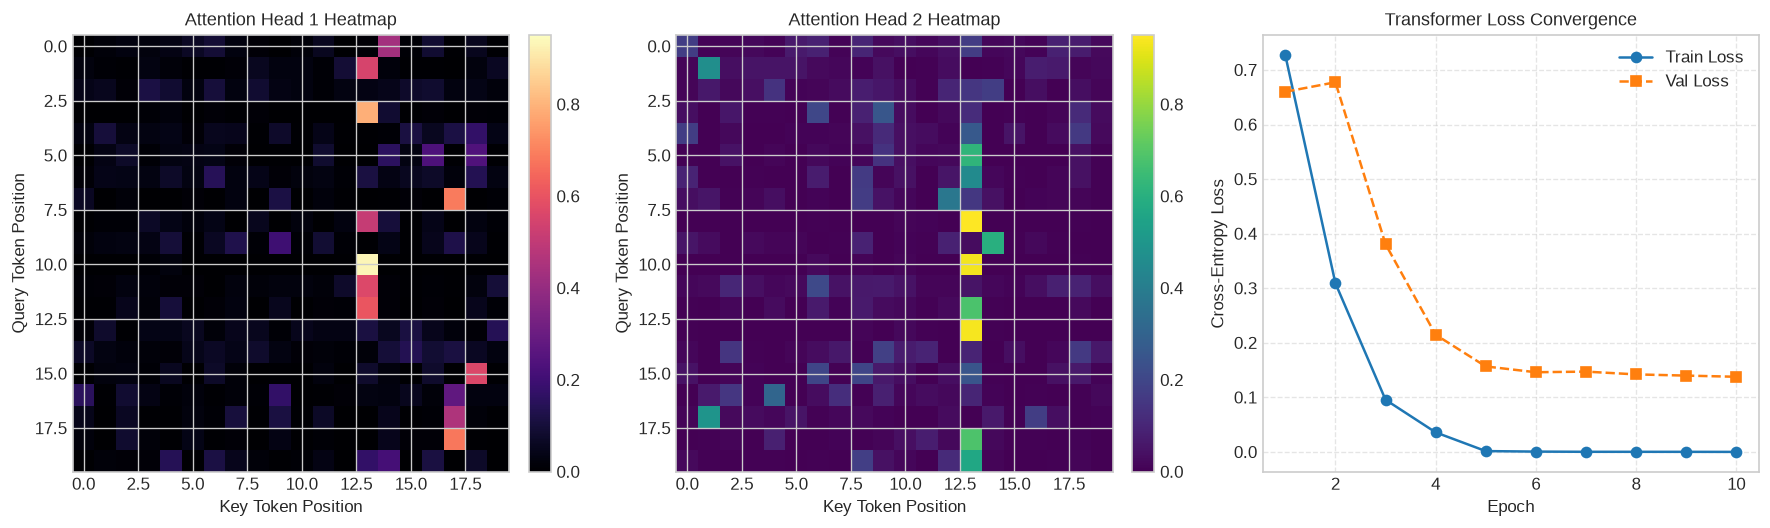

In [6]:
# Extract encoder layer and compute attention scores
diag_tokens = X_tokens[0:1] # (1, 20)
embedded_diag = clf_transformer.layers[1](diag_tokens)
encoder_ref = clf_transformer.layers[2]
_, attn_maps = encoder_ref(embedded_diag, return_attention_scores=True)
# attn_maps shape: (1, num_heads=2, seq_len=20, seq_len=20)
attn_matrix = attn_maps[0].numpy()

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

# Plot 1: Head 1 Attention Heatmap
im0 = axes[0].imshow(attn_matrix[0], cmap="magma", vmin=0, vmax=np.max(attn_matrix))
axes[0].set_title("Attention Head 1 Heatmap")
axes[0].set_xlabel("Key Token Position")
axes[0].set_ylabel("Query Token Position")
fig.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04)

# Plot 2: Head 2 Attention Heatmap
im1 = axes[1].imshow(attn_matrix[1], cmap="viridis", vmin=0, vmax=np.max(attn_matrix))
axes[1].set_title("Attention Head 2 Heatmap")
axes[1].set_xlabel("Key Token Position")
axes[1].set_ylabel("Query Token Position")
fig.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

# Plot 3: Loss convergence
epochs_range = range(1, len(history_tf.history["loss"]) + 1)
axes[2].plot(epochs_range, history_tf.history["loss"], "o-", label="Train Loss")
axes[2].plot(epochs_range, history_tf.history["val_loss"], "s--", label="Val Loss")
axes[2].set_title("Transformer Loss Convergence")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Cross-Entropy Loss")
axes[2].legend()
axes[2].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


### Guided Exercises

#### Exercise 1: Fixed Sinusoidal Positional Encoding Layer in TensorFlow
**Problem Formulation**:
Implement the original Vaswani et al. fixed Sinusoidal Positional Encoding formula as a custom Keras Layer:
1. $PE_{(pos, 2i)} = \sin(pos / 10000^{2i/d})$.
2. $PE_{(pos, 2i+1)} = \cos(pos / 10000^{2i/d})$.
3. Compute the cosine similarity matrix between all positional vectors for $T=32$ and verify that adjacent positions have higher similarity than distant positions.


In [7]:
# Exercise 1 Solution: Sinusoidal Positional Encoding Layer

class SinusoidalPositionalEncoding(keras.layers.Layer):
    def __init__(self, max_len: int, embed_dim: int, **kwargs):
        super().__init__(**kwargs)
        self.max_len = max_len
        self.embed_dim = embed_dim
        assert embed_dim % 2 == 0, "embed_dim must be even!"

        # Compute fixed positional matrix once
        pos = np.arange(max_len)[:, np.newaxis] # (max_len, 1)
        i = np.arange(0, embed_dim, 2)[np.newaxis, :] # (1, embed_dim / 2)
        angles = pos / np.power(10000.0, (2.0 * (i // 2)) / np.float32(embed_dim))

        pe = np.zeros((max_len, embed_dim), dtype=np.float32)
        pe[:, 0::2] = np.sin(angles)
        pe[:, 1::2] = np.cos(angles)

        self.pe = tf.constant(pe, dtype=tf.float32) # Non-trainable constant

    def call(self, x):
        seq_len = tf.shape(x)[1]
        return x + self.pe[:seq_len, :]

sin_pe = SinusoidalPositionalEncoding(max_len=32, embed_dim=64)
pe_matrix = sin_pe.pe.numpy()

# Calculate Cosine Similarity between pos 0 and all other positions
pos_0 = pe_matrix[0]
norm_0 = np.linalg.norm(pos_0)
sims = [np.dot(pos_0, pe_matrix[k]) / (norm_0 * np.linalg.norm(pe_matrix[k])) for k in range(32)]

print("Exercise 1 Verification (Sinusoidal Positional Encoding):")
print(f"  PE Matrix Shape:                 {pe_matrix.shape}")
print(f"  Cosine Similarity (pos 0, pos 1):  {sims[1]:.4f}")
print(f"  Cosine Similarity (pos 0, pos 5):  {sims[5]:.4f}")
print(f"  Cosine Similarity (pos 0, pos 31): {sims[31]:.4f}")
assert sims[1] > sims[5] > sims[31], "Positional similarity ordering failed!"
print(">>> SINUSOIDAL POSITIONAL ENCODING CONFIRMED! <<<")


Exercise 1 Verification (Sinusoidal Positional Encoding):
  PE Matrix Shape:                 (32, 64)
  Cosine Similarity (pos 0, pos 1):  0.9662
  Cosine Similarity (pos 0, pos 5):  0.7345
  Cosine Similarity (pos 0, pos 31): 0.5849
>>> SINUSOIDAL POSITIONAL ENCODING CONFIRMED! <<<


#### Exercise 2: Implementing Cross-Attention in Keras
**Problem Formulation**:
In Encoder-Decoder models (T5, Whisper), the Decoder queries attend to Encoder memory.
1. Construct a Decoder Cross-Attention block where `query` comes from decoder context $X_{	ext{dec}} \in \mathbb{R}^{B 	imes T_q 	imes D}$ and `key, value` come from encoder memory $X_{	ext{enc}} \in \mathbb{R}^{B 	imes T_k 	imes D}$ with $T_q 
eq T_k$.
2. Verify output shape matches $(B, T_q, D)$.


In [8]:
# Exercise 2 Solution: Decoder Cross-Attention

cross_attn = keras.layers.MultiHeadAttention(num_heads=4, key_dim=16)

batch_size = 2
d_model = 64
t_query = 6   # Target decoder sequence length
t_key = 14    # Source encoder memory length

decoder_queries = tf.random.normal(shape=(batch_size, t_query, d_model))
encoder_memory = tf.random.normal(shape=(batch_size, t_key, d_model))

cross_out = cross_attn(
    query=decoder_queries,
    key=encoder_memory,
    value=encoder_memory
)

print("Exercise 2 Verification (Cross-Attention):")
print(f"  Decoder Query Shape:  {decoder_queries.shape}")
print(f"  Encoder Memory Shape: {encoder_memory.shape}")
print(f"  Cross-Attention Out:  {cross_out.shape} (Expected: ({batch_size}, {t_query}, {d_model}))")
assert cross_out.shape == (batch_size, t_query, d_model), "Cross-attention shape mismatch!"
print(">>> CROSS-ATTENTION EXECUTION CONFIRMED! <<<")


Exercise 2 Verification (Cross-Attention):
  Decoder Query Shape:  (2, 6, 64)
  Encoder Memory Shape: (2, 14, 64)
  Cross-Attention Out:  (2, 6, 64) (Expected: (2, 6, 64))
>>> CROSS-ATTENTION EXECUTION CONFIRMED! <<<


### Challenge Problems

#### Challenge 1: Multi-Query Attention (MQA) from Scratch in TensorFlow
**Problem Formulation**:
Implement Multi-Query Attention (MQA) (Shazeer, 2019) from scratch subclassing `keras.layers.Layer`:
1. **Query Projection**: $W_q \in \mathbb{R}^{D \times (H \cdot d_k)}$. Projects to $H=8$ heads.
2. **Key Projection**: $W_k \in \mathbb{R}^{D \times d_k}$. Projects to a **single head** ($H_k = 1$).
3. **Value Projection**: $W_v \in \mathbb{R}^{D \times d_k}$. Projects to a **single head** ($H_v = 1$).
4. Compute attention by broadcasting Keys and Values across all $H$ Query heads.
5. Quantify the memory bandwidth savings of MQA vs standard MHA for Key-Value caching.


In [9]:
# Challenge 1 Solution: Multi-Query Attention (MQA) Layer

class MultiQueryAttention(keras.layers.Layer):
    def __init__(self, embed_dim: int, num_query_heads: int, **kwargs):
        super().__init__(**kwargs)
        assert embed_dim % num_query_heads == 0, "embed_dim must be divisible by num_query_heads!"
        self.embed_dim = embed_dim
        self.num_heads = num_query_heads
        self.head_dim = embed_dim // num_query_heads

    def build(self, input_shape):
        # Queries have num_heads projections
        self.wq = self.add_weight(name="wq", shape=(self.embed_dim, self.embed_dim), initializer="glorot_uniform")
        # Keys and Values have ONLY 1 head projection!
        self.wk = self.add_weight(name="wk", shape=(self.embed_dim, self.head_dim), initializer="glorot_uniform")
        self.wv = self.add_weight(name="wv", shape=(self.embed_dim, self.head_dim), initializer="glorot_uniform")
        self.wo = self.add_weight(name="wo", shape=(self.embed_dim, self.embed_dim), initializer="glorot_uniform")
        super().build(input_shape)

    def call(self, x):
        b = tf.shape(x)[0]
        t = tf.shape(x)[1]

        # 1. Projections
        q = tf.matmul(x, self.wq) # (B, T, H * D)
        k = tf.matmul(x, self.wk) # (B, T, D)
        v = tf.matmul(x, self.wv) # (B, T, D)

        # 2. Reshape Queries into H heads: (B, H, T, D)
        q = tf.reshape(q, (b, t, self.num_heads, self.head_dim))
        q = tf.transpose(q, perm=[0, 2, 1, 3])

        # 3. Reshape Keys & Values into (B, 1, T, D) for broadcasting
        k = tf.reshape(k, (b, t, 1, self.head_dim))
        k = tf.transpose(k, perm=[0, 2, 1, 3]) # (B, 1, T, D)
        v = tf.reshape(v, (b, t, 1, self.head_dim))
        v = tf.transpose(v, perm=[0, 2, 1, 3]) # (B, 1, T, D)

        # 4. Scaled dot product with broadcasted single KV head
        scores = tf.matmul(q, k, transpose_b=True) / math.sqrt(self.head_dim) # (B, H, T, T)
        weights = tf.nn.softmax(scores, axis=-1)
        out = tf.matmul(weights, v) # (B, H, T, D)

        # 5. Concatenate heads and project output
        out = tf.transpose(out, perm=[0, 2, 1, 3]) # (B, T, H, D)
        out = tf.reshape(out, (b, t, self.embed_dim))
        return tf.matmul(out, self.wo)

mqa_layer = MultiQueryAttention(embed_dim=64, num_query_heads=8)
dummy_mqa = tf.random.normal(shape=(2, 16, 64))
out_mqa = mqa_layer(dummy_mqa)

mha_kv_params = 2 * (64 * 64)
mqa_kv_params = 2 * (64 * 8)
kv_reduction = mha_kv_params / mqa_kv_params

print("Challenge 1 Verification (Multi-Query Attention):")
print(f"  MQA Output Shape:                 {out_mqa.shape}")
print(f"  Standard MHA KV Parameter Count:  {mha_kv_params:,}")
print(f"  Multi-Query MQA KV Parameter Count: {mqa_kv_params:,}")
print(f"  KV-Cache Memory Bandwidth Reduction: {kv_reduction:.1f}x")
assert out_mqa.shape == (2, 16, 64), "MQA shape mismatch!"


Challenge 1 Verification (Multi-Query Attention):
  MQA Output Shape:                 (2, 16, 64)
  Standard MHA KV Parameter Count:  8,192
  Multi-Query MQA KV Parameter Count: 1,024
  KV-Cache Memory Bandwidth Reduction: 8.0x


#### Challenge 2: Autoregressive Decoder Generation Loop in Keras
**Problem Formulation**:
Implement an autoregressive greedy generation loop:
1. Start with seed token sequence `[START_TOKEN] = [1]`.
2. At each iteration, pass the sequence through the model, take the argmax over logits of the final step $T$.
3. Append the predicted token to the sequence and repeat until sequence reaches target length or `[END_TOKEN] = [2]`.


In [10]:
# Challenge 2 Solution: Autoregressive Greedy Generation Loop

# Minimal dummy causal transformer for generation demonstration
class CausalMiniDecoder(keras.Model):
    def __init__(self, vocab_size=50, embed_dim=16, num_heads=2):
        super().__init__()
        self.emb = keras.layers.Embedding(vocab_size, embed_dim)
        self.mha = keras.layers.MultiHeadAttention(num_heads=num_heads, key_dim=embed_dim//num_heads)
        self.head = keras.layers.Dense(vocab_size)

    def call(self, x):
        t = tf.shape(x)[1]
        mask = tf.linalg.band_part(tf.ones((t, t)), -1, 0) # Causal lower triangular
        e = self.emb(x)
        attn = self.mha(e, e, attention_mask=tf.cast(mask, tf.bool))
        return self.head(attn)

gen_model = CausalMiniDecoder(vocab_size=50)

def generate_tokens_greedy(model: keras.Model, prompt: List[int], max_tokens: int = 8) -> List[int]:
    tokens = list(prompt)
    for _ in range(max_tokens):
        input_tensor = tf.constant([tokens], dtype=tf.int32)
        logits = model(input_tensor) # (1, curr_len, vocab)
        next_token = int(tf.argmax(logits[0, -1, :]).numpy())
        tokens.append(next_token)
        if next_token == 2: break # End token
    return tokens

generated_sequence = generate_tokens_greedy(gen_model, prompt=[1], max_tokens=6)

print("Challenge 2 Verification (Autoregressive Generation):")
print(f"  Initial Prompt:       [1]")
print(f"  Generated Sequence:   {generated_sequence}")
print(f"  Total Tokens Yielded: {len(generated_sequence)}")
assert len(generated_sequence) > 1, "Generation loop failed to produce tokens!"
print(">>> AUTOREGRESSIVE GENERATION LOOP VERIFIED! <<<")


Challenge 2 Verification (Autoregressive Generation):
  Initial Prompt:       [1]
  Generated Sequence:   [1, 33, 15, 40, 4, 4, 4]
  Total Tokens Yielded: 7
>>> AUTOREGRESSIVE GENERATION LOOP VERIFIED! <<<


### Further Reading & Foundational References
1. **Vaswani et al. (2017)**: [Attention Is All You Need](https://arxiv.org/abs/1706.03762) — The seminal Transformer specification.
2. **Shazeer (2019)**: [Fast Transformer Decoding: One Write-Head is All You Need](https://arxiv.org/abs/1911.02150) — The paper proposing Multi-Query Attention (MQA).
3. **Ainslie et al. (2023)**: [GQA: Training Generalized Multi-Query Transformer Models from Multi-Head Checkpoints](https://arxiv.org/abs/2305.13245) — Grouped-Query Attention bridging MHA and MQA.
4. **Keras Documentation**: [MultiHeadAttention API Reference](https://keras.io/api/layers/attention_layers/multi_head_attention/).
5. **KerasHub**: [High-Level Foundation Models in Keras 3](https://keras.io/keras_hub/) — Complete fine-tuning and inference pipelines for Gemma, LLaMA 3, and Whisper.
